# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into
*distinct arms* with Crest terminal. A non-branching manifold instead shows a **single
developmental gradient** along the trajectory body with an inverse terminal end. In Zhang
2021 that gradient is the **posterior-somitogenesis → neural-crest** axis: pSom is high over
the manifold body and falls along pseudotime (ρ ≈ −0.27) while Crest rises to a terminal
end (ρ ≈ +0.48), the two being strongly anti-correlated in space (r = −0.91). Gastrulation
co-varies with pSom and is weakly structured (an *early* embryonic programme, largely spent
in this adult carcinoma). The single-axis, inverse-terminal pattern **is present**, so
**Gate 2 = GO**; with no bifurcation the cross-repression test is **Gate 3 = NA**. Crest is
terminal (not enriched on a Gast arm), so no inversion flag.
Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('global module means (raw score_genes):',
      {m: round(float(adata.obs[m].mean()),4) for m in ['Gast','pSom','Crest']})

cells: 11218 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 74/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present
global module means (raw score_genes): {'Gast': -0.0336, 'pSom': 0.0846, 'Crest': -0.0596}


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature for this dataset: (i) the dominant
developmental contrast is pSom vs Crest (strong spatial anti-correlation); (ii) along
pseudotime pSom declines and Crest rises (Crest terminal); (iii) Gast is weakly structured
and co-varies with pSom (early programme, spent).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
# COMPUTE the inversion flag (C2): §2 says FLAG if Crest enriches the GAST pole/arm rather
# than sitting at the pSom-leaning terminus. The robust, trajectory-aligned test is WHERE along
# pseudotime each module's high-decile sits: if Crest-high is at the OPPOSITE end from Gast-high
# (Crest terminal, Gast toward the root), that is the normal terminal-Crest pattern -> no flag;
# if Crest-high coincides with the Gast-high pole, that is the inversion -> flag.
crest_hi = (adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)).values
gast_hi  = (adata.obs['Gast_sm']  >= adata.obs['Gast_sm'].quantile(0.9)).values
pt_crest_hi = tn[crest_hi].mean()
pt_gast_hi  = tn[gast_hi].mean()
print(f'Neural-crest-high decile mean pseudotime = {pt_crest_hi:.2f} (terminal if ~1)')
print(f'Gastrulation-high decile mean pseudotime  = {pt_gast_hi:.2f} (root-ward if ~0)')
# inversion if Crest-high sits at (or before) the Gast-high pole rather than clearly after it
inversion = pt_crest_hi <= pt_gast_hi
flag = 'FLAG (Crest co-enriches the Gast pole)' if inversion else 'no inversion flag (Crest terminal, Gast root-ward)'
print(f'inversion test: Crest-high at/before Gast-high pole? {inversion} -> {flag}')
# COMPUTE the Gate 2 verdict from the geography metrics (C2): a non-branching GO requires the
# single-axis, inverse-terminal-Crest pattern to be present, i.e. Crest anti-correlated with the
# dominant pSom axis in space AND rising along pseudotime (terminal). Both are computed above.
r_crest_psom = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
rho_crest_t,_ = spearmanr(t, adata.obs['Crest_sm'])
pattern_present = (r_crest_psom < 0) and (rho_crest_t > 0) and (pt_crest_hi > 0.5)
gate2 = 'GO' if pattern_present else 'NO-GO'
flag_txt = ' [FLAGGED: Crest enriches the Gast pole]' if inversion else ''
print(f'Gate 2 test: Crest-pSom spatial r={r_crest_psom:+.2f}(<0), Crest-pseudotime rho={rho_crest_t:+.2f}(>0), '
      f'Crest-high pt={pt_crest_hi:.2f}(>0.5) -> pattern present? {pattern_present}')
print(f'Gate 2: single pSom->Crest gradient + inverse terminal Crest -> {gate2} (non-branching){flag_txt}')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.61
  Crest_sm vs Gast_sm: r = +0.39
  Crest_sm vs pSom_sm: r = -0.91
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.226
  pSom_sm: rho = -0.283
  Crest_sm: rho = +0.480
Neural-crest-high decile mean pseudotime = 0.72 (terminal if ~1)
Gastrulation-high decile mean pseudotime  = 0.38 (root-ward if ~0)
inversion test: Crest-high at/before Gast-high pole? False -> no inversion flag (Crest terminal, Gast root-ward)
Gate 2 test: Crest-pSom spatial r=-0.91(<0), Crest-pseudotime rho=+0.48(>0), Crest-high pt=0.72(>0.5) -> pattern present? True
Gate 2: single pSom->Crest gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma,
**raw** (not smoothed) score per cell so 10x dropout is visible (binding: deliverable UMAPs
show raw scores; smoothing is used only for the analysis geography above). Colorbar ticks
data-driven.

<cell 5>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 5>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 5>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


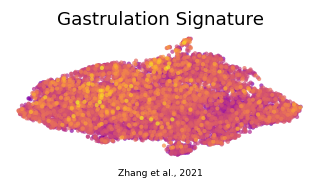

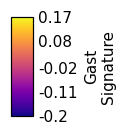

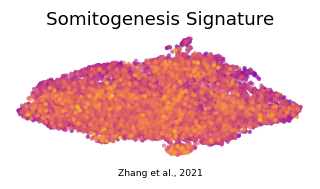

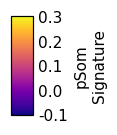

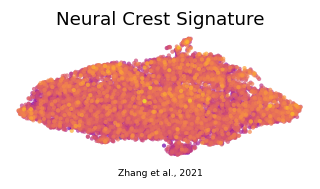

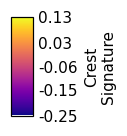

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    plt.show()
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (11218, 23065)
